# 03 — Evaluación walk-forward de correctores TSMOM

> La pregunta es si los correctores aprendidos sobre TSMOM conservan utilidad económica al reentrenarse cronológicamente. Se usan tres evaluaciones sucesivas de XLE; los resultados son exploratorios porque XLE y las configuraciones ya han sido estudiados.

## <b>Block 01 — Datos, baseline y cronología</b>

> Se conserva el baseline de las notebooks 01 y 02: momentum logarítmico de 126 sesiones, volatilidad EWMA $\lambda=0.94$, objetivo anual de 12%, tope 1 y decisión al cierre de $t$ aplicada al retorno de $t+1$. Gold local es la única fuente.

In [1]:
from pathlib import Path
import math
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
import torch
from torch import nn
torch.set_num_threads(1)

SEED, EPOCHS, LEARNING_RATE = 42, 80, 0.01
START = pd.Timestamp('2018-01-02')
MOMENTUM_FEATURES = (21, 63, 126)
EWMA_LAMBDA, EWMA_WARMUP = 0.94, 20
TARGET_VOLATILITY, MAX_EXPOSURE = 0.12, 1.00
LOOKBACK, ADJUSTMENT_LIMIT = 63, 0.20
RESEARCH_COST_PER_TURNOVER = 0.0005  # 5 bps por unidad; supuesto de investigación.
CYCLES = [
    ('2024', pd.Timestamp('2023-12-31'), pd.Timestamp('2024-01-01'), pd.Timestamp('2024-12-31')),
    ('2025', pd.Timestamp('2024-12-31'), pd.Timestamp('2025-01-01'), pd.Timestamp('2025-12-31')),
    ('2026', pd.Timestamp('2025-12-31'), pd.Timestamp('2026-01-01'), None),
]

def find_repo_root(start=Path.cwd()):
    for candidate in (start.resolve(), *start.resolve().parents):
        if (candidate / 'Momentum_systematic_strategies').is_dir():
            return candidate
    raise FileNotFoundError('No se encontró la raíz del repositorio.')

ROOT = find_repo_root()
GOLD_PATH = ROOT / 'Momentum_systematic_strategies' / 'data' / 'gold' / 'daily_series' / 'etf' / 'XLE.parquet'
gold = pl.read_parquet(GOLD_PATH).select('session_date', 'adjusted_close').sort('session_date')
GOLD_END = pd.Timestamp(gold.get_column('session_date').max())
print('Gold XLE: {} → {}'.format(gold.get_column('session_date').min(), GOLD_END.date()))

frame = pd.DataFrame(gold.filter(pl.col('session_date') >= START.date()).to_dict(as_series=False)).rename(columns={'session_date': 'decision_date'})
frame['decision_date'] = pd.to_datetime(frame['decision_date'])
frame['ret_1d'] = frame['adjusted_close'].pct_change()
for horizon in MOMENTUM_FEATURES:
    frame['mom_{}'.format(horizon)] = np.log(frame['adjusted_close'] / frame['adjusted_close'].shift(horizon))

ret = frame['ret_1d'].to_numpy(float)
variance = np.full(len(frame), np.nan)
first_valid = np.flatnonzero(np.isfinite(ret))[0]
initial_index = first_valid + EWMA_WARMUP - 1
variance[initial_index] = np.mean(ret[first_valid:initial_index + 1] ** 2)
for i in range(initial_index + 1, len(frame)):
    variance[i] = EWMA_LAMBDA * variance[i - 1] + (1 - EWMA_LAMBDA) * ret[i] ** 2
frame['ewma_vol_annual'] = np.sqrt(variance) * math.sqrt(252)
frame['baseline_position'] = np.where(frame['mom_126'] > 0, np.minimum(MAX_EXPOSURE, TARGET_VOLATILITY / frame['ewma_vol_annual']), 0.0)
frame['return_date'] = frame['decision_date'].shift(-1)
frame['next_return'] = frame['ret_1d'].shift(-1)
feature_columns = ['ret_1d', 'mom_21', 'mom_63', 'mom_126', 'ewma_vol_annual']
frame['ready'] = frame[feature_columns].notna().all(axis=1).astype(int).rolling(LOOKBACK).sum().eq(LOOKBACK)
frame['_row'] = np.arange(len(frame))
sample = frame.loc[frame['ready'] & frame['next_return'].notna()].copy().reset_index(drop=True)
assert (sample['return_date'] > sample['decision_date']).all()
assert sample['baseline_position'].between(0, 1).all()
print('Muestra causal: {} → {}; {:,} decisiones'.format(sample.decision_date.min().date(), sample.return_date.max().date(), len(sample)))

Gold XLE: 2018-01-02 → 2026-11-17
Muestra causal: 2018-10-01 → 2026-11-17; 2,043 decisiones


## <b>Block 02 — Correctores congelados</b>

> En cada ciclo se reinicializan con semilla 42 una LSTM de 8 unidades y ventana 63, una red feedforward de 8 unidades que ve solo las cinco variables actuales y un desplazamiento constante. Todas parten de corrección cero, entrenan 80 épocas y maximizan el mismo Sharpe neto.

In [2]:
class AnchoredLSTM(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.lstm = nn.LSTM(n_features, 8, num_layers=1, batch_first=True)
        self.residual = nn.Linear(8, 1)
        nn.init.zeros_(self.residual.weight); nn.init.zeros_(self.residual.bias)
    def forward(self, x):
        hidden, _ = self.lstm(x)
        return ADJUSTMENT_LIMIT * torch.tanh(self.residual(hidden[:, -1, :]).squeeze(-1))

class AnchoredFeedForward(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.hidden, self.residual = nn.Linear(n_features, 8), nn.Linear(8, 1)
        nn.init.zeros_(self.residual.weight); nn.init.zeros_(self.residual.bias)
    def forward(self, x):
        return ADJUSTMENT_LIMIT * torch.tanh(self.residual(torch.tanh(self.hidden(x))).squeeze(-1))

class ConstantCorrection(nn.Module):
    def __init__(self):
        super().__init__(); self.raw_adjustment = nn.Parameter(torch.zeros(()))
    def forward(self, x):
        return ADJUSTMENT_LIMIT * torch.tanh(self.raw_adjustment).expand(x.shape[0])

def train_model(model, inputs, train_idx, baseline_tensor, returns_tensor):
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    index = torch.tensor(train_idx, dtype=torch.long)
    for _ in range(EPOCHS):
        optimizer.zero_grad()
        position = torch.clamp(baseline_tensor[index] + model(inputs[index]), 0.0, 1.0)
        turnover = torch.cat(((position[1:2] - position[:1]).abs(), (position[2:] - position[1:-1]).abs()))
        net = position[1:] * returns_tensor[index][1:] - RESEARCH_COST_PER_TURNOVER * turnover
        loss = -(net.mean() / net.std(unbiased=False).clamp_min(1e-6) * math.sqrt(252))
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
    return model

def parameter_count(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

parameter_table = pd.DataFrame({
    'estrategia': ['TSMOM baseline', 'Corrección constante', 'Feedforward actual', 'LSTM 63 sesiones'],
    'parámetros entrenables': [0, parameter_count(ConstantCorrection()), parameter_count(AnchoredFeedForward(5)), parameter_count(AnchoredLSTM(5))],
})
parameter_table

,estrategia,parámetros entrenables
0,TSMOM baseline,0
1,Corrección constante,1
2,Feedforward actual,57
3,LSTM 63 sesiones,489


## <b>Block 03 — Reentrenamiento walk-forward</b>

> Un modelo queda disponible después del último retorno incluido en su entrenamiento. La sesión previa a su primera decisión conserva la posición anterior y su P&L, sin rebalanceo ni coste; al inicio de 2024 esa posición es efectivo. El cambio de peso se cobra solo cuando el nuevo modelo decide.

In [3]:
labels = ['TSMOM baseline', 'Corrección constante', 'Feedforward actual', 'LSTM 63 sesiones']
daily_parts, previous_parts, causal_rows, boundary_rows = [], [], [], []
previous_position = {label: 0.0 for label in labels}
previous_position_old = previous_position.copy()

for cycle, train_end, evaluation_start, evaluation_end in CYCLES:
    evaluation_end = GOLD_END if evaluation_end is None else min(evaluation_end, GOLD_END)
    train_idx = np.flatnonzero((sample['return_date'] <= train_end).to_numpy())
    available_date = sample.loc[train_idx, 'return_date'].max()
    target_idx = np.flatnonzero(((sample['return_date'] >= evaluation_start) & (sample['return_date'] <= evaluation_end)).to_numpy())
    active_idx = target_idx[sample.loc[target_idx, 'decision_date'].to_numpy() > available_date]
    bridge_idx = target_idx[sample.loc[target_idx, 'decision_date'].to_numpy() <= available_date]
    assert len(train_idx) and len(active_idx) and len(target_idx) == len(active_idx) + len(bridge_idx)
    assert sample.loc[active_idx, 'decision_date'].min() > available_date

    train_rows = sample.loc[train_idx, '_row'].to_numpy()
    raw = frame[feature_columns].to_numpy(dtype=np.float32)
    mean, std = raw[train_rows].mean(0), np.maximum(raw[train_rows].std(0), 1e-8)
    scaled = (raw - mean) / std
    rows = sample['_row'].to_numpy()
    sequence = np.stack([scaled[row - LOOKBACK + 1:row + 1] for row in rows]).astype(np.float32)
    current = scaled[rows].astype(np.float32)
    assert np.array_equal(sequence[:, -1, :], current)

    seq_t, cur_t = torch.tensor(sequence), torch.tensor(current)
    base_t = torch.tensor(sample['baseline_position'].to_numpy(dtype=np.float32))
    ret_t = torch.tensor(sample['next_return'].to_numpy(dtype=np.float32))
    np.random.seed(SEED); random.seed(SEED); torch.manual_seed(SEED)
    lstm = train_model(AnchoredLSTM(5), seq_t, train_idx, base_t, ret_t)
    feedforward = train_model(AnchoredFeedForward(5), cur_t, train_idx, base_t, ret_t)
    constant = train_model(ConstantCorrection(), cur_t, train_idx, base_t, ret_t)
    with torch.no_grad():
        all_positions = {
            'TSMOM baseline': sample['baseline_position'].to_numpy(),
            'Corrección constante': np.clip(sample['baseline_position'].to_numpy() + constant(cur_t).numpy(), 0, 1),
            'Feedforward actual': np.clip(sample['baseline_position'].to_numpy() + feedforward(cur_t).numpy(), 0, 1),
            'LSTM 63 sesiones': np.clip(sample['baseline_position'].to_numpy() + lstm(seq_t).numpy(), 0, 1),
        }
    active_dates = sample.loc[active_idx, 'return_date'].to_numpy()
    active_returns = sample.loc[active_idx, 'next_return'].to_numpy()
    bridge_dates = sample.loc[bridge_idx, 'return_date'].to_numpy()
    bridge_returns = sample.loc[bridge_idx, 'next_return'].to_numpy()
    for label, position in all_positions.items():
        weights = position[active_idx]
        # Réplica de la contabilidad anterior: omite la sesión puente.
        turnover_old = np.r_[abs(weights[0] - previous_position_old[label]), abs(np.diff(weights))]
        costs_old = RESEARCH_COST_PER_TURNOVER * turnover_old
        previous_parts.append(pd.DataFrame({'cycle': cycle, 'return_date': active_dates, 'estrategia': label, 'position': weights, 'gross': weights * active_returns, 'costs': costs_old, 'net': weights * active_returns - costs_old, 'turnover': turnover_old, 'origen': 'modelo nuevo'}))
        previous_position_old[label] = weights[-1]

        # Contabilidad corregida: mantener la posición previa hasta la primera decisión nueva.
        if len(bridge_idx):
            held = np.full(len(bridge_idx), previous_position[label])
            daily_parts.append(pd.DataFrame({'cycle': cycle, 'return_date': bridge_dates, 'estrategia': label, 'position': held, 'gross': held * bridge_returns, 'costs': np.zeros(len(bridge_idx)), 'net': held * bridge_returns, 'turnover': np.zeros(len(bridge_idx)), 'origen': 'posición arrastrada'}))
        turnover = np.r_[abs(weights[0] - previous_position[label]), abs(np.diff(weights))]
        costs = RESEARCH_COST_PER_TURNOVER * turnover
        daily_parts.append(pd.DataFrame({'cycle': cycle, 'return_date': active_dates, 'estrategia': label, 'position': weights, 'gross': weights * active_returns, 'costs': costs, 'net': weights * active_returns - costs, 'turnover': turnover, 'origen': 'modelo nuevo'}))
        previous_position[label] = weights[-1]
    causal_rows.append({'ciclo': cycle, 'modelo disponible tras': available_date.date(), 'primera decisión': sample.loc[active_idx, 'decision_date'].min().date(), 'primer retorno del modelo': pd.Timestamp(active_dates[0]).date(), 'sesiones arrastradas': len(bridge_idx), 'retornos': len(target_idx)})
    boundary_rows.append({'ciclo': cycle, 'primer retorno arrastrado': pd.Timestamp(bridge_dates[0]).date() if len(bridge_idx) else None, 'primera decisión nueva': sample.loc[active_idx, 'decision_date'].min().date()})

daily = pd.concat(daily_parts, ignore_index=True).sort_values(['estrategia', 'return_date']).reset_index(drop=True)
daily_previous = pd.concat(previous_parts, ignore_index=True).sort_values(['estrategia', 'return_date']).reset_index(drop=True)
causal_schedule, boundaries = pd.DataFrame(causal_rows), pd.DataFrame(boundary_rows)
expected_dates = pd.DatetimeIndex(frame.loc[(frame['decision_date'] >= pd.Timestamp('2024-01-01')) & (frame['decision_date'] <= GOLD_END), 'decision_date'])
assert daily.groupby('estrategia').size().nunique() == 1
assert daily.groupby('estrategia')['return_date'].apply(tuple).nunique() == 1
assert pd.DatetimeIndex(daily.loc[daily['estrategia'] == 'TSMOM baseline', 'return_date']).equals(expected_dates)
display(causal_schedule)
boundaries

,ciclo,modelo disponible tras,primera decisión,primer retorno del modelo,sesiones arrastradas,retornos
0,2024,2023-12-29,2024-01-02,2024-01-03,1,252
1,2025,2024-12-31,2025-01-02,2025-01-03,1,250
2,2026,2025-12-31,2026-01-02,2026-01-05,1,221


,ciclo,primer retorno arrastrado,primera decisión nueva
0,2024,2024-01-02,2024-01-02
1,2025,2025-01-02,2025-01-02
2,2026,2026-01-02,2026-01-02


## <b>Block 04 — Resultados por año y trayectoria concatenada</b>

> Todas las estrategias comparten cada sesión Gold del periodo evaluado. La tabla anterior frente a corregida conserva la versión con la omisión anual únicamente para reconciliación; la trayectoria y las métricas principales usan la contabilidad corregida.

,sesión,posición,retorno neto,turnover
0,puente: sin rebalanceo,0.6,0.0600,0.0
1,modelo nuevo: rebalanceo,0.4,-0.0201,0.2


,estrategia,retorno neto compuesto (%) anterior,volatilidad anual (%) anterior,Sharpe neto anterior,max drawdown (%) anterior,exposición media (%) anterior,turnover total anterior,costes totales (%) anterior,retorno neto compuesto (%) corregido,volatilidad anual (%) corregido,Sharpe neto corregido,max drawdown (%) corregido,exposición media (%) corregido,turnover total corregido,costes totales (%) corregido
0,Corrección constante,6.512,13.309,0.233,-22.470,56.748,33.712,1.686,8.416,13.316,0.278,-22.365,56.637,33.712,1.686
1,Feedforward actual,0.975,8.695,0.083,-17.579,35.066,34.159,1.708,1.981,8.697,0.122,-17.579,34.986,34.159,1.708
2,LSTM 63 sesiones,7.901,9.225,0.335,-15.270,37.441,46.032,2.302,8.982,9.224,0.371,-15.270,37.351,46.032,2.302
3,TSMOM baseline,0.538,11.108,0.073,-22.057,44.952,33.875,1.694,1.945,11.115,0.116,-22.057,44.858,33.875,1.694


,cycle,estrategia,retorno neto compuesto (%),volatilidad anual (%),Sharpe neto,max drawdown (%),exposición media (%),turnover total,costes totales (%)
0,2024,Corrección constante,-12.611,11.532,-1.111,-15.204,57.224,13.866,0.693
1,2025,Corrección constante,-4.666,12.620,-0.318,-12.468,49.100,16.174,0.809
2,2026,Corrección constante,30.134,15.614,2.003,-10.059,64.493,3.671,0.184
3,2024,Feedforward actual,-9.559,7.342,-1.331,-10.559,33.620,11.145,0.557
4,2025,Feedforward actual,-5.359,8.420,-0.617,-9.864,30.158,14.753,0.738
5,2026,Feedforward actual,19.145,10.175,2.015,-6.652,42.004,8.261,0.413
6,2024,LSTM 63 sesiones,-9.486,7.268,-1.335,-10.404,33.121,10.850,0.542
7,2025,LSTM 63 sesiones,-2.206,9.910,-0.177,-8.840,41.085,22.390,1.119
8,2026,LSTM 63 sesiones,23.120,10.219,2.373,-8.094,37.952,12.793,0.640
9,2024,TSMOM baseline,-13.280,9.949,-1.382,-14.197,45.837,14.033,0.702


,estrategia,retorno neto compuesto (%),volatilidad anual (%),Sharpe neto,max drawdown (%),exposición media (%),turnover total,costes totales (%),Δ neto diario medio vs TSMOM (bps),Δ neto suma vs TSMOM (%)
0,Corrección constante,8.416,13.316,0.278,-22.365,56.637,33.712,1.686,0.959,6.932
1,Feedforward actual,1.981,8.697,0.122,-17.579,34.986,34.159,1.708,-0.091,-0.655
2,LSTM 63 sesiones,8.982,9.224,0.371,-15.270,37.351,46.032,2.302,0.846,6.119
3,TSMOM baseline,1.945,11.115,0.116,-22.057,44.858,33.875,1.694,0.000,0.000


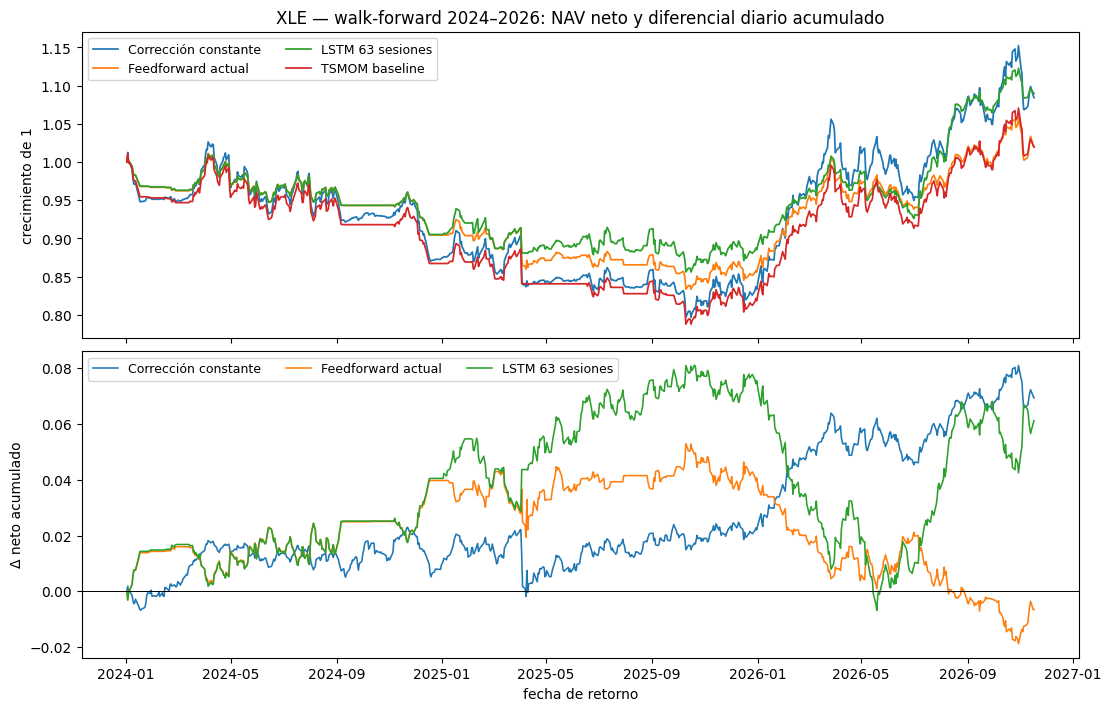

In [4]:
def metrics_for(part):
    net = part['net'].to_numpy(); nav = np.r_[1.0, np.cumprod(1 + net)]
    vol = net.std(ddof=0) * math.sqrt(252)
    return pd.Series({
        'retorno neto compuesto (%)': (nav[-1] - 1) * 100,
        'volatilidad anual (%)': vol * 100,
        'Sharpe neto': net.mean() / max(net.std(ddof=0), 1e-8) * math.sqrt(252),
        'max drawdown (%)': (nav / np.maximum.accumulate(nav) - 1).min() * 100,
        'exposición media (%)': part['position'].mean() * 100,
        'turnover total': part['turnover'].sum(),
        'costes totales (%)': part['costs'].sum() * 100,
    })

# Test sintético: el retorno puente usa el peso heredado y el primer rebalanceo cobra el cambio real.
synthetic_previous, synthetic_return, synthetic_new = 0.60, 0.10, 0.40
synthetic_bridge_net = synthetic_previous * synthetic_return
synthetic_turnover = abs(synthetic_new - synthetic_previous)
synthetic_new_net = synthetic_new * (-0.05) - RESEARCH_COST_PER_TURNOVER * synthetic_turnover
assert np.isclose(synthetic_bridge_net, 0.06) and np.isclose(synthetic_turnover, 0.20)
synthetic_test = pd.DataFrame({'sesión': ['puente: sin rebalanceo', 'modelo nuevo: rebalanceo'], 'posición': [synthetic_previous, synthetic_new], 'retorno neto': [synthetic_bridge_net, synthetic_new_net], 'turnover': [0.0, synthetic_turnover]})

yearly = daily.groupby(['cycle', 'estrategia'], sort=False).apply(metrics_for, include_groups=False).reset_index()
combined = daily.groupby('estrategia', sort=False).apply(metrics_for, include_groups=False).reset_index()
combined_previous = daily_previous.groupby('estrategia', sort=False).apply(metrics_for, include_groups=False).reset_index()
baseline_net = daily.loc[daily['estrategia'] == 'TSMOM baseline', ['return_date', 'net']].set_index('return_date')['net']
daily_delta = daily.join(baseline_net.rename('baseline_net'), on='return_date')
delta_summary = daily_delta.groupby('estrategia', sort=False).apply(lambda x: pd.Series({'Δ neto diario medio vs TSMOM (bps)': (x['net'] - x['baseline_net']).mean() * 1e4, 'Δ neto suma vs TSMOM (%)': (x['net'] - x['baseline_net']).sum() * 100}), include_groups=False).reset_index()
combined = combined.merge(delta_summary, on='estrategia')
reconciliation = combined_previous.merge(combined.drop(columns=['Δ neto diario medio vs TSMOM (bps)', 'Δ neto suma vs TSMOM (%)']), on='estrategia', suffixes=(' anterior', ' corregido'))
display(synthetic_test.round(4))
display(reconciliation.round(3))
display(yearly.round(3))
display(combined.round(3))

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True, layout='constrained')
for label, part in daily.groupby('estrategia', sort=False):
    part = part.sort_values('return_date'); nav = np.cumprod(1 + part['net'].to_numpy())
    axes[0].plot(part['return_date'], nav, label=label, lw=1.25)
    if label != 'TSMOM baseline':
        axes[1].plot(part['return_date'], np.cumsum(part['net'].to_numpy() - baseline_net.loc[part['return_date']].to_numpy()), label=label, lw=1.15)
axes[0].set_title('XLE — walk-forward 2024–2026: NAV neto y diferencial diario acumulado')
axes[0].set_ylabel('crecimiento de 1'); axes[0].legend(ncol=2, fontsize=9)
axes[1].axhline(0, color='black', lw=0.7); axes[1].set_ylabel('Δ neto acumulado'); axes[1].set_xlabel('fecha de retorno'); axes[1].legend(ncol=3, fontsize=9)
plt.show()

## <b>Conclusión del walk-forward</b>

- Cada observación de evaluación procede de un modelo reentrenado solo con retornos anteriores a su fecha de disponibilidad.
- La trayectoria corregida incluye las sesiones puente con la posición arrastrada; no omite P&L en los cambios anuales ni cobra un rebalanceo inexistente.
- La comparación por ciclos y la trayectoria concatenada describen estabilidad temporal, no seleccionan retrospectivamente una estrategia ganadora.
- La selección previa de XLE y la exploración de notebooks anteriores limitan la independencia de cualquier resultado favorable.
- Los costes son un supuesto de investigación y esta simulación de retornos diarios no representa ejecución con órdenes y fills.

## <b>Block 05 — Atribución económica de las correcciones aprendidas</b>

> Para cada fecha se compara cada corrector con el TSMOM aplicado a ese mismo retorno. El estado long/cash corresponde al peso baseline conocido en la decisión $t$. La separación entre retornos positivos y negativos de XLE usa información ex post: describe contribuciones realizadas y no es una señal predictiva.

,estrategia,año,estado baseline en t,sesiones,Δ exposición media (pp),Δ bruto suma (%),Δ costes suma (%),Δ neto suma (%)
0,Corrección constante,2024,cash,91.0,11.441,2.940,0.000,2.940
1,Corrección constante,2024,long,161.0,11.356,-2.010,-0.008,-2.001
2,Corrección constante,2025,cash,107.0,11.964,1.888,0.000,1.888
3,Corrección constante,2025,long,143.0,11.967,-0.623,0.000,-0.623
4,Corrección constante,2026,long,221.0,12.015,4.728,-0.000,4.728
5,Feedforward actual,2024,cash,91.0,0.021,0.012,-0.072,0.084
6,Feedforward actual,2024,long,161.0,-19.135,3.816,-0.072,3.889
7,Feedforward actual,2025,cash,107.0,6.164,0.438,-0.018,0.457
8,Feedforward actual,2025,long,143.0,-16.809,-0.419,-0.053,-0.366
9,Feedforward actual,2026,long,221.0,-10.474,-4.489,0.229,-4.718


,estrategia,retorno XLE ex post,sesiones,Δ exposición media (pp),Δ bruto suma (%),Δ costes suma (%),Δ neto suma (%)
0,Corrección constante,positivo,407.0,11.812,47.742,0.001,47.741
1,Corrección constante,negativo,312.0,11.772,-40.818,-0.009,-40.809
2,Feedforward actual,positivo,407.0,-9.461,-34.403,0.018,-34.421
3,Feedforward actual,negativo,312.0,-10.475,33.762,-0.004,33.766
4,LSTM 63 sesiones,positivo,407.0,-6.946,-24.398,0.444,-24.842
5,LSTM 63 sesiones,negativo,312.0,-8.399,31.125,0.163,30.962


LSTM 2025: Δ exposición media +3.95 pp; Δ bruto +3.813%; Δ costes +0.311%; Δ neto +3.502%.
Identidad Δ neto = Δ bruto − Δ costes y métricas walk-forward previas: sí.


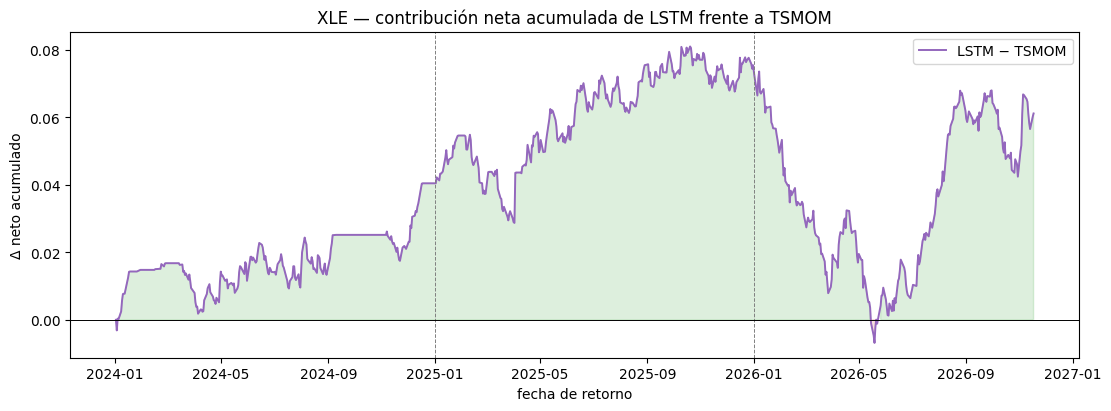

In [5]:
metrics_before_attribution = combined.copy(deep=True)
baseline_daily = daily.loc[daily['estrategia'] == 'TSMOM baseline', ['return_date', 'position', 'gross', 'costs', 'net']].rename(columns={'position': 'baseline_position', 'gross': 'baseline_gross', 'costs': 'baseline_costs', 'net': 'baseline_net'})
attribution = daily.loc[daily['estrategia'] != 'TSMOM baseline'].merge(baseline_daily, on='return_date', validate='many_to_one')
attribution['Δ exposición'] = attribution['position'] - attribution['baseline_position']
attribution['Δ bruto'] = attribution['gross'] - attribution['baseline_gross']
attribution['Δ costes'] = attribution['costs'] - attribution['baseline_costs']
attribution['Δ neto'] = attribution['net'] - attribution['baseline_net']
assert np.allclose(attribution['Δ neto'], attribution['Δ bruto'] - attribution['Δ costes'])

# Se infiere el retorno del activo desde gross / position usando únicamente daily.
observed = daily.loc[daily['position'].abs() > 1e-12, ['return_date', 'gross', 'position']].copy()
observed['xle_return'] = observed['gross'] / observed['position']
assert observed.groupby('return_date')['xle_return'].apply(lambda x: np.allclose(x, x.iloc[0])).all()
xle_return = observed.groupby('return_date')['xle_return'].first()
attribution = attribution.join(xle_return.rename('xle_return'), on='return_date')
attribution['año'] = attribution['return_date'].dt.year
attribution['estado baseline en t'] = np.where(attribution['baseline_position'] > 0, 'long', 'cash')
attribution['retorno XLE ex post'] = np.where(attribution['xle_return'] > 0, 'positivo', np.where(attribution['xle_return'] < 0, 'negativo', 'cero'))

def summarize(part):
    return pd.Series({'sesiones': len(part), 'Δ exposición media (pp)': part['Δ exposición'].mean() * 100, 'Δ bruto suma (%)': part['Δ bruto'].sum() * 100, 'Δ costes suma (%)': part['Δ costes'].sum() * 100, 'Δ neto suma (%)': part['Δ neto'].sum() * 100})

by_year_state = attribution.groupby(['estrategia', 'año', 'estado baseline en t'], sort=False).apply(summarize, include_groups=False).reset_index()
by_return_sign = attribution.loc[attribution['retorno XLE ex post'].isin(['positivo', 'negativo'])].groupby(['estrategia', 'retorno XLE ex post'], sort=False).apply(summarize, include_groups=False).reset_index()
display(by_year_state.round(3))
display(by_return_sign.round(3))

lstm_attr = attribution.loc[attribution['estrategia'] == 'LSTM 63 sesiones'].sort_values('return_date')
lstm_2025 = lstm_attr.loc[lstm_attr['año'] == 2025]
print('LSTM 2025: Δ exposición media {:+.2f} pp; Δ bruto {:+.3f}%; Δ costes {:+.3f}%; Δ neto {:+.3f}%.'.format(lstm_2025['Δ exposición'].mean() * 100, lstm_2025['Δ bruto'].sum() * 100, lstm_2025['Δ costes'].sum() * 100, lstm_2025['Δ neto'].sum() * 100))
assert combined.equals(metrics_before_attribution)
print('Identidad Δ neto = Δ bruto − Δ costes y métricas walk-forward previas: sí.')

fig, ax = plt.subplots(figsize=(11, 4), layout='constrained')
cumulative_delta = lstm_attr['Δ neto'].cumsum()
ax.plot(lstm_attr['return_date'], cumulative_delta, color='tab:purple', lw=1.4, label='LSTM − TSMOM')
ax.fill_between(lstm_attr['return_date'], 0, cumulative_delta, where=cumulative_delta >= 0, color='tab:green', alpha=0.16)
ax.fill_between(lstm_attr['return_date'], 0, cumulative_delta, where=cumulative_delta < 0, color='tab:red', alpha=0.14)
for date in [pd.Timestamp('2025-01-01'), pd.Timestamp('2026-01-01')]: ax.axvline(date, color='grey', lw=0.7, ls='--')
ax.axhline(0, color='black', lw=0.7); ax.set_title('XLE — contribución neta acumulada de LSTM frente a TSMOM'); ax.set_ylabel('Δ neto acumulado'); ax.set_xlabel('fecha de retorno'); ax.legend()
plt.show()